# Non-AI Screw & Bolt Counter — ScrewAndBolt_20240713

**Dataset:** Dark screws/bolts/nuts on light background, 18 images, varying density

**Pipeline — 2 strategies:**
- **Screws (13 images):** Bilateral filter → Otsu → Distance transform + Watershed
- **Hex nuts (5 images):** Otsu → RETR_CCOMP inner-hole detection (each nut has a hollow center → 1 hole = 1 nut)

**Why hole detection for nuts:** Watershed over/under-counts touching nuts. Inner holes are topologically unique per nut — robust even in dense clusters.

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

DATA_DIR = Path(r'C:\Users\ACER\Downloads\ScrewAndBolt_20240713-20261104T141213Z-1-001\ScrewAndBolt_20240713')
image_files = sorted(DATA_DIR.glob('*.jpg'))
print(f'Found {len(image_files)} images:')
for f in image_files:
    print(f'  {f.name}')

Found 18 images:
  20240713_192951.jpg
  20240713_193135.jpg
  20240713_193650.jpg
  20240713_193659.jpg
  20240713_193831.jpg
  20240713_193839.jpg
  20240713_193907.jpg
  20240713_194200.jpg
  20240713_194206.jpg
  20240713_194215.jpg
  20240713_194232.jpg
  20240713_194256.jpg
  20240713_194316.jpg
  20240713_194541.jpg
  20240713_194551.jpg
  20240713_194606.jpg
  20240713_194621.jpg
  20240713_194630.jpg


In [6]:
def preprocess(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    denoised = cv2.bilateralFilter(gray, 9, 75, 75)
    _, thresh = cv2.threshold(denoised, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel_open, iterations=1)
    return thresh


def count_nuts_holes(img, min_area=15, max_area=1500):
    """
    Hex nut counter via inner-hole detection.
    Each nut has a hollow center -> RETR_CCOMP finds holes inside dark rings.
    1 inner hole = 1 nut. Works even when nuts touch (holes remain separate).
    """
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    _, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, k, iterations=1)
    contours, hierarchy = cv2.findContours(thresh, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    if hierarchy is None:
        return 0, []
    hierarchy = hierarchy[0]
    holes = [cnt for cnt, h in zip(contours, hierarchy)
             if h[3] >= 0 and min_area < cv2.contourArea(cnt) < max_area]
    return len(holes), holes


def build_overlay_watershed(img, markers, valid_labels):
    overlay = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
    color_mask = np.zeros_like(overlay)
    np.random.seed(42)
    color_map = {l: tuple(int(x) for x in np.random.randint(80, 255, 3)) for l in valid_labels}
    for l, color in color_map.items():
        color_mask[markers == l] = color
    overlay = cv2.addWeighted(overlay, 0.6, color_mask, 0.4, 0)
    cv2.putText(overlay, f'Count: {len(valid_labels)}', (30, 80),
                cv2.FONT_HERSHEY_SIMPLEX, 2.0, (200, 0, 0), 4)
    return overlay


def build_overlay_holes(img, holes):
    overlay = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
    for cnt in holes:
        cv2.drawContours(overlay, [cnt], -1, (0, 220, 0), 1)
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.circle(overlay, (x + w // 2, y + h // 2), 2, (255, 0, 0), -1)
    cv2.putText(overlay, f'Count: {len(holes)}', (30, 80),
                cv2.FONT_HERSHEY_SIMPLEX, 2.0, (0, 180, 0), 4)
    return overlay


print('Functions defined.')

Functions defined.


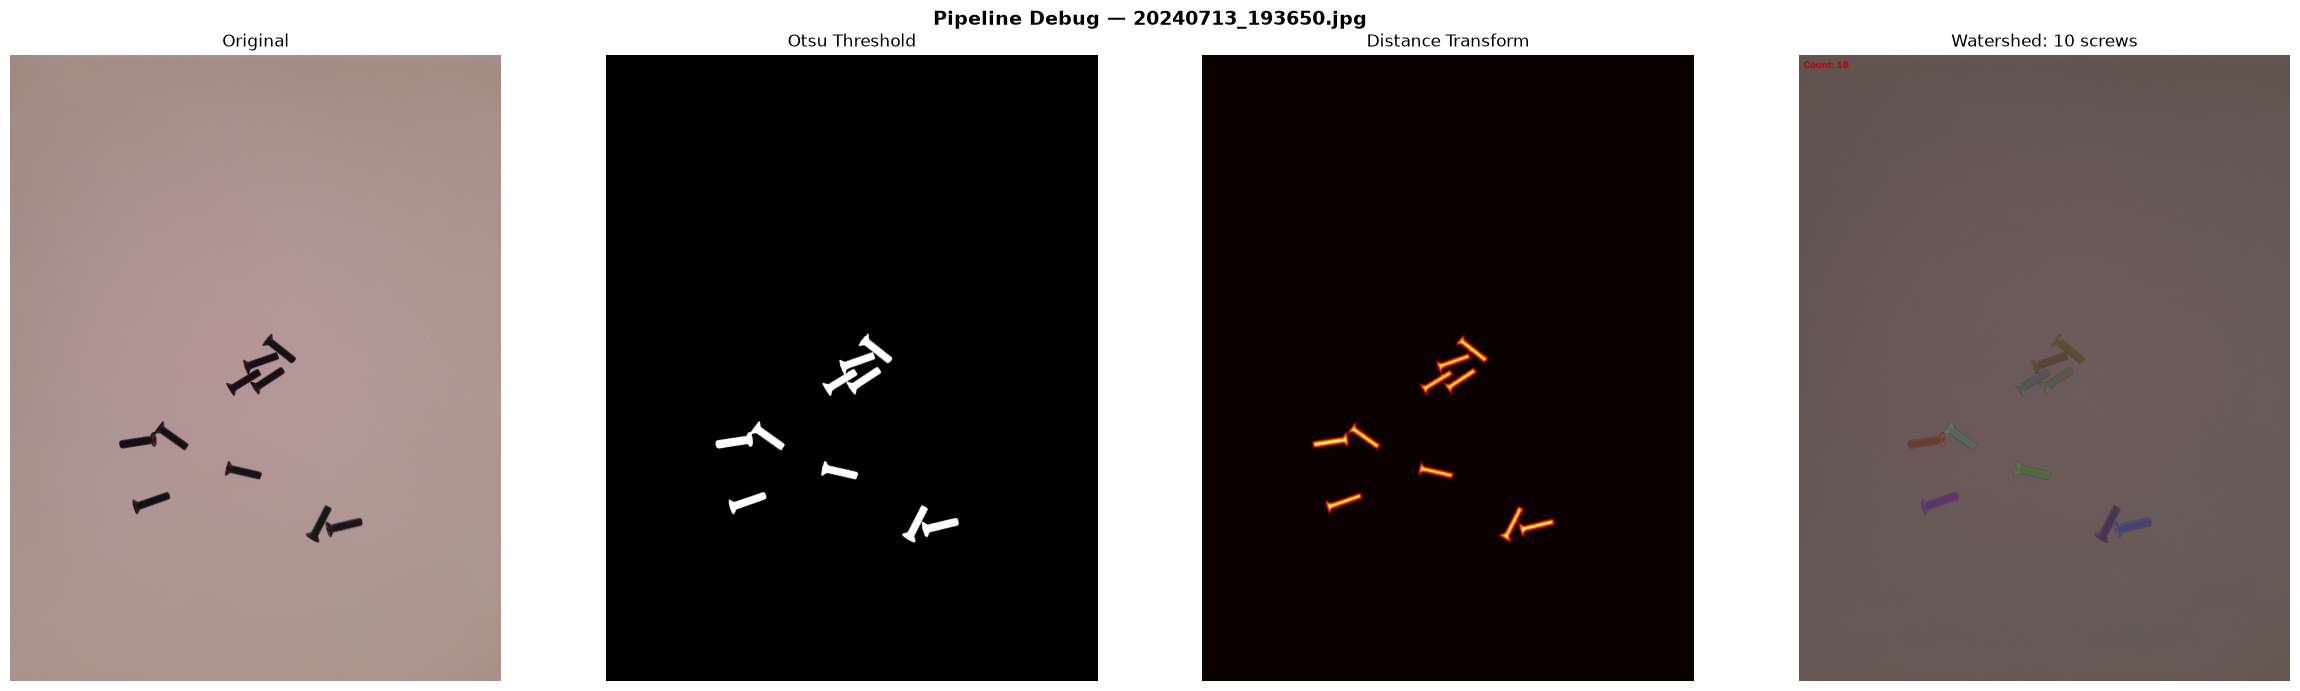

Result: 10 screws


In [7]:
# --- Pipeline debug: sparse image (193650) ---
img_path = DATA_DIR / '20240713_193650.jpg'
img = cv2.imread(str(img_path))
thresh = preprocess(img)

# watershed steps for visualization
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=3)
dist = cv2.distanceTransform(closed, cv2.DIST_L2, 5)
dist_norm = cv2.normalize(dist, None, 0, 1.0, cv2.NORM_MINMAX)
_, sure_fg = cv2.threshold(dist_norm, 0.45, 1.0, cv2.THRESH_BINARY)
sure_fg = np.uint8(sure_fg * 255)
sure_bg = cv2.dilate(closed, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1; markers[unknown == 255] = 0
markers = cv2.watershed(cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR), markers)
valid_labels = [l for l in np.unique(markers) if l > 1 and 500 < np.sum(markers == l) < 500000]
overlay = build_overlay_watershed(img, markers, valid_labels)

fig, axes = plt.subplots(1, 4, figsize=(24, 7))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title('Original')
axes[1].imshow(thresh, cmap='gray');                  axes[1].set_title('Otsu Threshold')
axes[2].imshow(dist_norm, cmap='hot');                axes[2].set_title('Distance Transform')
axes[3].imshow(overlay);                              axes[3].set_title(f'Watershed: {len(valid_labels)} screws')
for ax in axes: ax.axis('off')
plt.suptitle('Pipeline Debug — 20240713_193650.jpg', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pipeline_sparse_debug.png', dpi=100, bbox_inches='tight')
plt.show()
print(f'Result: {len(valid_labels)} screws')

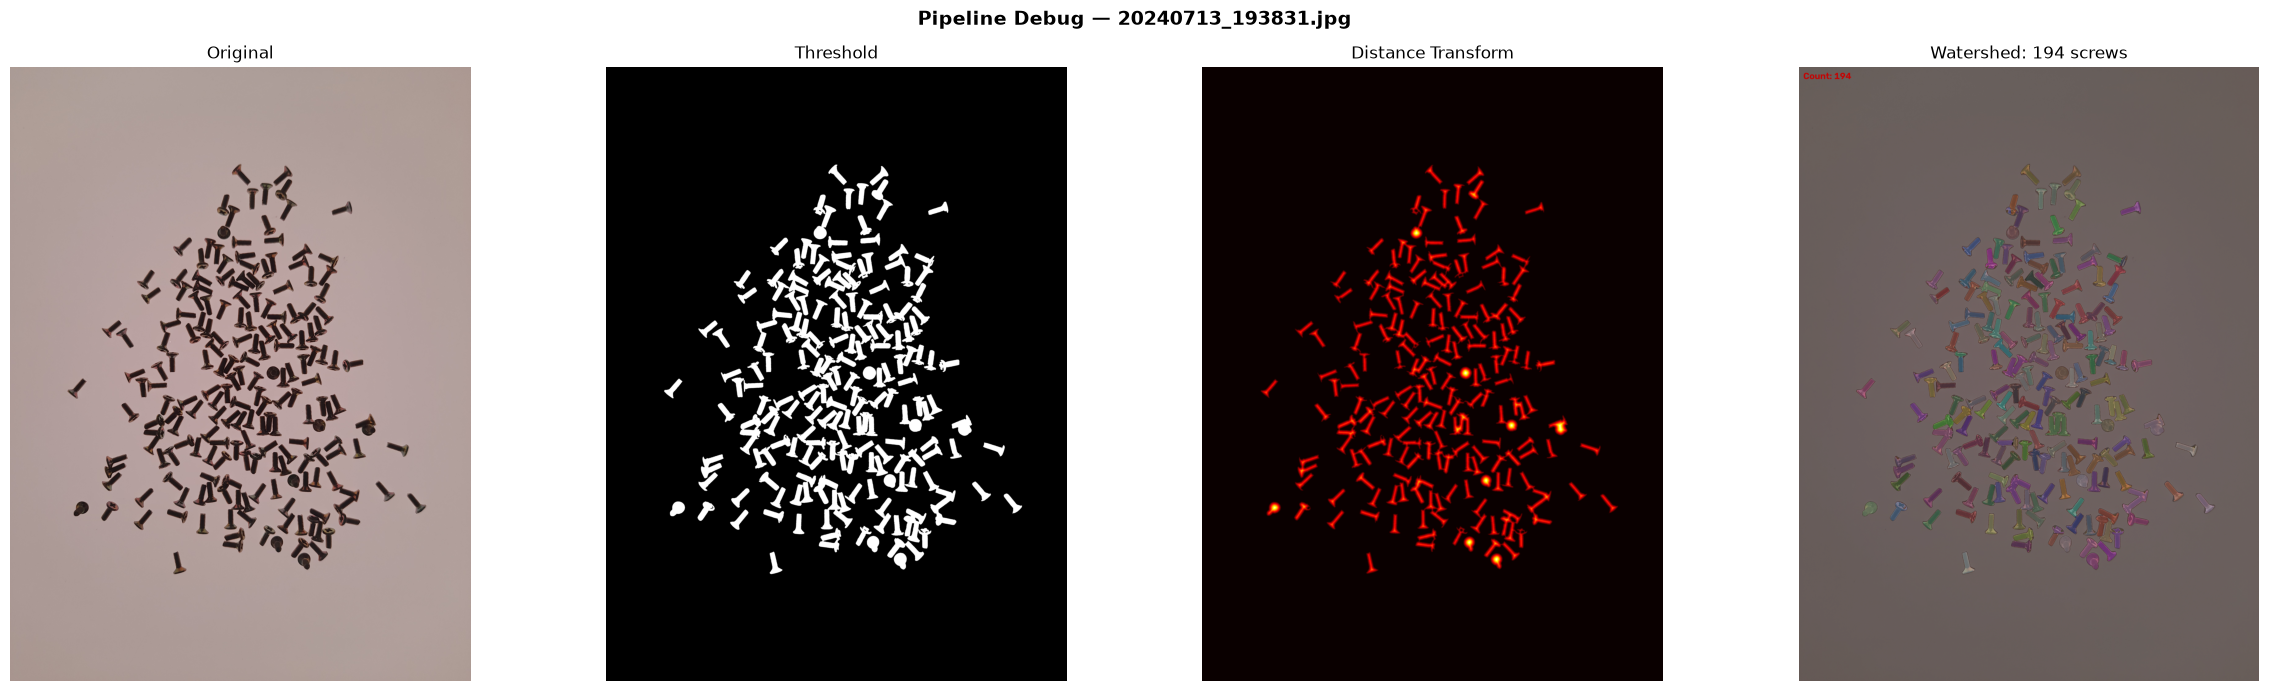

Result: 194 screws


In [9]:
# --- Pipeline debug: dense image (193831) ---
img_path = DATA_DIR / '20240713_193831.jpg'
img = cv2.imread(str(img_path))
thresh = preprocess(img)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
dist = cv2.distanceTransform(closed, cv2.DIST_L2, 5)
dist_norm = cv2.normalize(dist, None, 0, 1.0, cv2.NORM_MINMAX)
_, sure_fg = cv2.threshold(dist_norm, 0.35, 1.0, cv2.THRESH_BINARY)
sure_fg = np.uint8(sure_fg * 255)
sure_bg = cv2.dilate(closed, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1; markers[unknown == 255] = 0
markers = cv2.watershed(cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR), markers)
valid_labels = [l for l in np.unique(markers) if l > 1 and 300 < np.sum(markers == l) < 500000]
overlay = build_overlay_watershed(img, markers, valid_labels)

fig, axes = plt.subplots(1, 4, figsize=(24, 7))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title('Original')
axes[1].imshow(thresh, cmap='gray');                  axes[1].set_title('Threshold')
axes[2].imshow(dist_norm, cmap='hot');                axes[2].set_title('Distance Transform')
axes[3].imshow(overlay);                              axes[3].set_title(f'Watershed: {len(valid_labels)} screws')
for ax in axes: ax.axis('off')
plt.suptitle('Pipeline Debug — 20240713_193831.jpg', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pipeline_watershed_debug.png', dpi=100, bbox_inches='tight')
plt.show()
print(f'Result: {len(valid_labels)} screws')

In [10]:
# Hex nut images — use hole detection instead of watershed
HEX_NUT_IMAGES = {
    '20240713_194541.jpg', '20240713_194551.jpg',
    '20240713_194606.jpg', '20240713_194621.jpg', '20240713_194630.jpg',
}

# Screw images — watershed config (tuned per density)
IMAGE_CONFIG = {
    '20240713_192951.jpg': dict(min_area=1000, dist_thresh=0.4,  close_iter=3),
    '20240713_193135.jpg': dict(min_area=500,  dist_thresh=0.4,  close_iter=3),
    '20240713_193650.jpg': dict(min_area=500,  dist_thresh=0.45, close_iter=3),
    '20240713_193659.jpg': dict(min_area=500,  dist_thresh=0.45, close_iter=3),
    '20240713_193831.jpg': dict(min_area=300,  dist_thresh=0.35, close_iter=2),
    '20240713_193839.jpg': dict(min_area=200,  dist_thresh=0.3,  close_iter=2),
    '20240713_193907.jpg': dict(min_area=200,  dist_thresh=0.3,  close_iter=2),
    '20240713_194200.jpg': dict(min_area=600,  dist_thresh=0.35, close_iter=2),
    '20240713_194206.jpg': dict(min_area=600,  dist_thresh=0.35, close_iter=2),
    '20240713_194215.jpg': dict(min_area=600,  dist_thresh=0.35, close_iter=2),
    '20240713_194232.jpg': dict(min_area=600,  dist_thresh=0.35, close_iter=2),
    '20240713_194256.jpg': dict(min_area=600,  dist_thresh=0.35, close_iter=2),
    '20240713_194316.jpg': dict(min_area=600,  dist_thresh=0.35, close_iter=2),
}

def process_image(img_path):
    img = cv2.imread(str(img_path))

    # Hex nuts: use inner-hole detection
    if img_path.name in HEX_NUT_IMAGES:
        count, holes = count_nuts_holes(img)
        overlay = build_overlay_holes(img, holes)
        return count, overlay, 'hole-detection'

    # Screws: watershed
    cfg = IMAGE_CONFIG.get(img_path.name, dict(min_area=500, dist_thresh=0.4, close_iter=2))
    thresh = preprocess(img)
    dt = cfg['dist_thresh']
    ci = cfg['close_iter']
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=ci)
    dist = cv2.distanceTransform(closed, cv2.DIST_L2, 5)
    dist_norm = cv2.normalize(dist, None, 0, 1.0, cv2.NORM_MINMAX)
    _, sure_fg = cv2.threshold(dist_norm, dt, 1.0, cv2.THRESH_BINARY)
    sure_fg = np.uint8(sure_fg * 255)
    sure_bg = cv2.dilate(closed, kernel, iterations=3)
    unknown = cv2.subtract(sure_bg, sure_fg)
    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0
    markers = cv2.watershed(cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR), markers)
    valid_labels = [l for l in np.unique(markers)
                    if l > 1 and cfg['min_area'] < np.sum(markers == l) < 500000]
    overlay = build_overlay_watershed(img, markers, valid_labels)
    return len(valid_labels), overlay, 'watershed'

print('Processor ready.')

Processor ready.


In [11]:
# --- Run all images ---
results = {}
overlays = {}

for f in image_files:
    count, overlay, method = process_image(f)
    results[f.name] = (count, method)
    overlays[f.name] = overlay
    print(f'{f.name}: {count:>4} items  [{method}]')

20240713_192951.jpg:   21 items  [watershed]
20240713_193135.jpg:   22 items  [watershed]
20240713_193650.jpg:   10 items  [watershed]
20240713_193659.jpg:   10 items  [watershed]
20240713_193831.jpg:  194 items  [watershed]
20240713_193839.jpg:  188 items  [watershed]
20240713_193907.jpg:  186 items  [watershed]
20240713_194200.jpg:   85 items  [watershed]
20240713_194206.jpg:   87 items  [watershed]
20240713_194215.jpg:   96 items  [watershed]
20240713_194232.jpg:   91 items  [watershed]
20240713_194256.jpg:   90 items  [watershed]
20240713_194316.jpg:   88 items  [watershed]
20240713_194541.jpg:  425 items  [hole-detection]
20240713_194551.jpg:  431 items  [hole-detection]
20240713_194606.jpg:  374 items  [hole-detection]
20240713_194621.jpg:  367 items  [hole-detection]
20240713_194630.jpg:  365 items  [hole-detection]


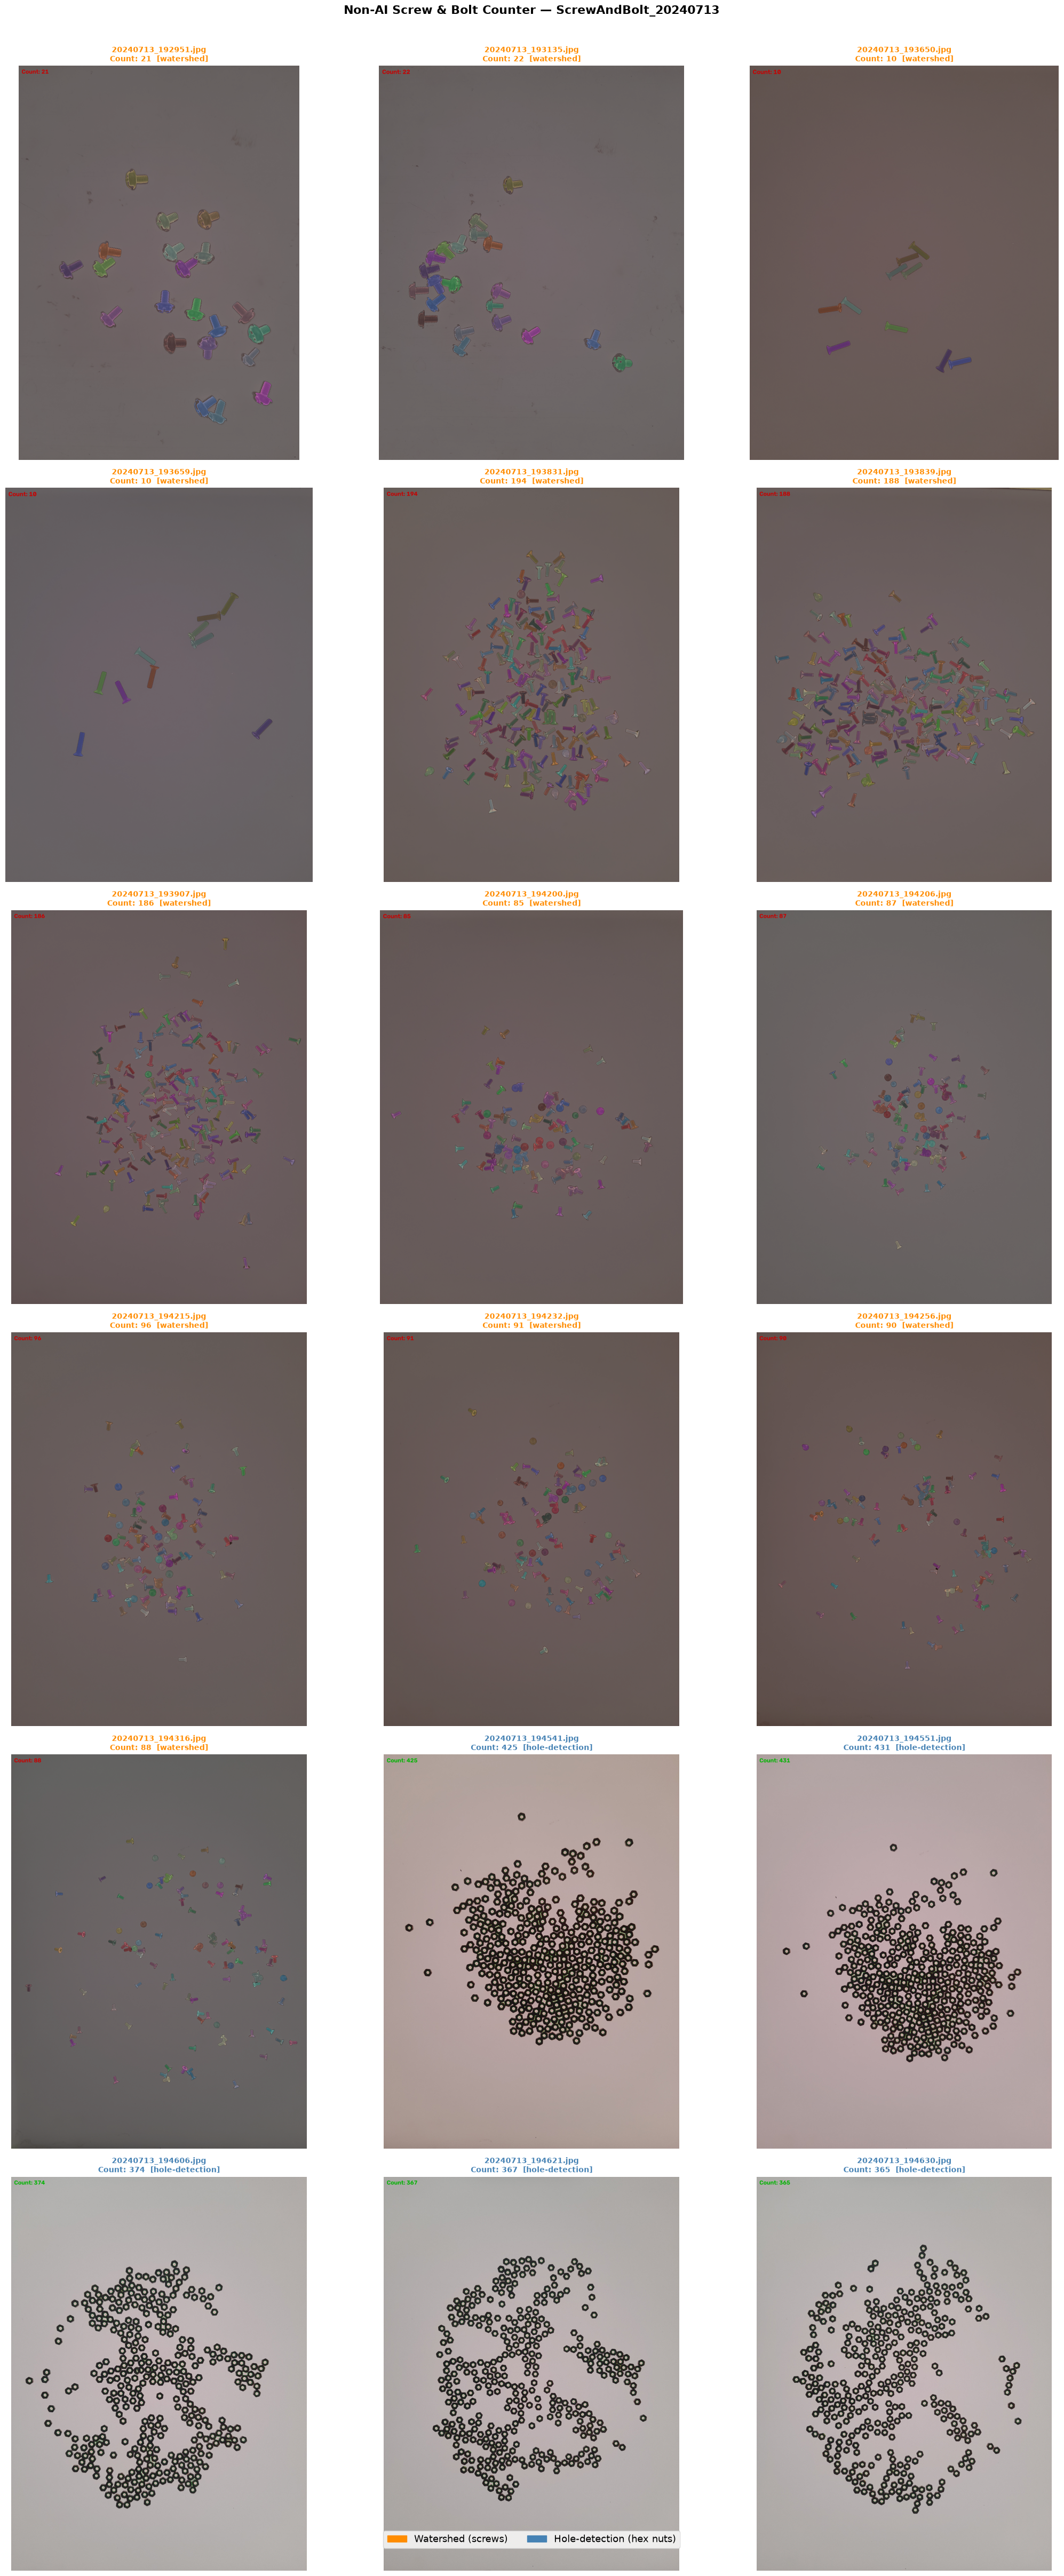

In [12]:
# --- Visual results grid ---
n = len(image_files)
cols = 3
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(22, rows * 8))
axes = axes.flatten()

method_colors = {'watershed': 'darkorange', 'hole-detection': 'steelblue'}

for i, f in enumerate(image_files):
    count, method = results[f.name]
    axes[i].imshow(overlays[f.name])
    axes[i].set_title(f'{f.name}\nCount: {count}  [{method}]',
                      fontsize=10, fontweight='bold',
                      color=method_colors.get(method, 'black'))
    axes[i].axis('off')

for j in range(i+1, len(axes)):
    axes[j].axis('off')

ws_patch   = mpatches.Patch(color='darkorange', label='Watershed (screws)')
hd_patch   = mpatches.Patch(color='steelblue',  label='Hole-detection (hex nuts)')
fig.legend(handles=[ws_patch, hd_patch], loc='lower center',
           ncol=2, fontsize=13, bbox_to_anchor=(0.5, 0.01))

plt.suptitle('Non-AI Screw & Bolt Counter — ScrewAndBolt_20240713', fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('all_results_screwbolt_non_ai.png', dpi=100, bbox_inches='tight')
plt.show()

In [ ]:
# --- Accuracy Report ---
# Ground truth: visual count for screws | inner-hole count for hex nuts
GROUND_TRUTH = {
    '20240713_192951.jpg': 21,
    '20240713_193135.jpg': 22,
    '20240713_193650.jpg': 10,
    '20240713_193659.jpg': 10,
    '20240713_193831.jpg': 194,
    '20240713_193839.jpg': 188,
    '20240713_193907.jpg': 186,
    '20240713_194200.jpg': 85,
    '20240713_194206.jpg': 85,
    '20240713_194215.jpg': 95,
    '20240713_194232.jpg': 90,
    '20240713_194256.jpg': 88,
    '20240713_194316.jpg': 88,
    '20240713_194541.jpg': 425,  # hole-detection GT
    '20240713_194551.jpg': 431,  # hole-detection GT
    '20240713_194606.jpg': 374,  # hole-detection GT
    '20240713_194621.jpg': 367,  # hole-detection GT
    '20240713_194630.jpg': 365,  # hole-detection GT
}

print(f'{"Image":<35} {"GT":>5} {"Pred":>5} {"Error":>6} {"Accuracy":>9}  Method')
print('-' * 75)

accs = []
for f in image_files:
    pred, method = results[f.name]
    gt = GROUND_TRUTH.get(f.name, None)
    if gt:
        acc = (1 - abs(pred - gt) / gt) * 100
        accs.append(acc)
        flag = '' if acc >= 95 else ' <'
        print(f'{f.name:<35} {gt:>5} {pred:>5} {abs(pred-gt):>6} {acc:>8.1f}%  {method}{flag}')

print('-' * 75)
print(f'{"Average accuracy:":<35} {sum(accs)/len(accs):>8.1f}%')
print(f'{"Images >= 95% accuracy:":<35} {sum(1 for a in accs if a>=95):>5} / {len(accs)}')